# UTS Pembelajaran Mesin – Regresi Linier Prediksi Volume Ekspor Udang (LPMHP DKI Jakarta)

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    df = pd.read_csv('dataset_pemsin.csv', sep=';', encoding='utf-8-sig', dtype={'volume': str})
    df['volume'] = df['volume'].str.replace(',', '.', regex=False)
except FileNotFoundError:
    df = pd.read_excel('dataset_pemsin.xlsx')
print(df.shape); print(df.dtypes); df.head()

(216, 5)
periode_data    int64
tahun           int64
bulan             str
jenis_ikan        str
volume            str
dtype: object


,periode_data,tahun,bulan,jenis_ikan,volume
0,2011,2011,OKTOBER,SETUHUK HITAM/MARLIN,103910
1,2011,2011,NOVEMBER,SETUHUK HITAM/MARLIN,62834
2,2011,2011,DESEMBER,SETUHUK HITAM/MARLIN,109645
3,2011,2011,JANUARI,TENGIRI,38213
4,2011,2011,FEBRUARI,TENGIRI,11930


## 1. EDA

Missing value:
periode_data    0
tahun           0
bulan           0
jenis_ikan      0
volume          1
dtype: int64
Jumlah nilai 0 : 5
count    2.150000e+02
mean     2.881118e+05
std      5.030927e+05
min      0.000000e+00
25%      5.873300e+04
50%      1.095100e+05
75%      2.051285e+05
max      2.515635e+06
Name: volume, dtype: float64
Outlier global (IQR): 30 baris


C:\Users\sitoh\AppData\Local\Temp\ipykernel_23768\3682232613.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0].boxplot([df.loc[df.jenis_ikan == k, 'volume'].dropna() for k in order], vert=False, tick_labels=order)


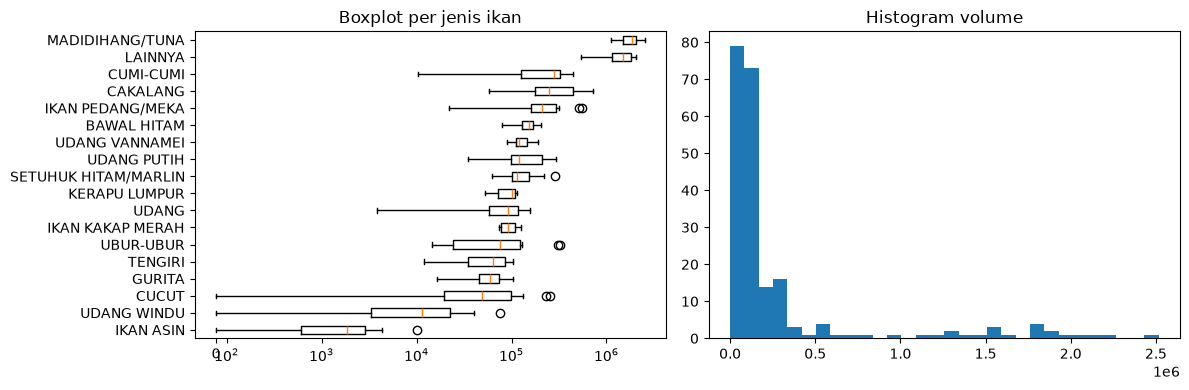

In [8]:
df['volume'] = pd.to_numeric(df['volume'].replace('-', np.nan), errors='coerce')
print('Missing value:'); print(df.isna().sum())
print('Jumlah nilai 0 :', (df['volume'] == 0).sum())
print(df['volume'].describe())

q1, q3 = df['volume'].quantile([.25, .75]); batas = q3 + 1.5*(q3-q1)
print('Outlier global (IQR):', (df['volume'] > batas).sum(), 'baris')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = df.groupby('jenis_ikan')['volume'].median().sort_values().index
ax[0].boxplot([df.loc[df.jenis_ikan == k, 'volume'].dropna() for k in order], vert=False, tick_labels=order)
ax[0].set_xscale('symlog', linthresh=1000); ax[0].set_title('Boxplot per jenis ikan')
ax[1].hist(df['volume'].dropna(), bins=30); ax[1].set_title('Histogram volume')
plt.tight_layout(); plt.show()

## 2. Data Preprocessing

In [9]:
df['volume'] = df.groupby('jenis_ikan')['volume'].transform(lambda s: s.fillna(s.median()))

def cap_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return s.clip(q1 - 1.5*iqr, q3 + 1.5*iqr)
before = df['volume'].copy()
df['volume'] = df.groupby('jenis_ikan')['volume'].transform(cap_iqr).clip(lower=0)
print('Jumlah nilai di-capping:', (before != df['volume']).sum())
print('Missing setelah cleaning:', df['volume'].isna().sum())

Jumlah nilai di-capping: 9
Missing setelah cleaning: 0


## 3. Persiapan Fitur
Kasus: memprediksi volume ekspor **bulan ini (Y)** dari volume **bulan sebelumnya (X, lag-1)** pada kelompok udang.

In [10]:
bulan = ['JANUARI','FEBRUARI','MARET','APRIL','MEI','JUNI','JULI','AGUSTUS','SEPTEMBER','OKTOBER','NOVEMBER','DESEMBER']
df['bulan_ke'] = df['bulan'].map({b: i+1 for i, b in enumerate(bulan)})

udang = df[df['jenis_ikan'].str.startswith('UDANG')].sort_values(['jenis_ikan', 'bulan_ke']).copy()
udang['lag1'] = udang.groupby('jenis_ikan')['volume'].shift(1)
data = udang.dropna(subset=['lag1'])

train = data[data['bulan_ke'] <= 9]    # Feb - Sep
test  = data[data['bulan_ke'] >= 10]   # Okt - Des (data uji berdasarkan urutan waktu)
print(len(udang), 'baris udang ->', len(data), 'pasangan | train', len(train), '| test', len(test))

48 baris udang -> 44 pasangan | train 32 | test 12


## 4. Pemodelan Regresi Linier & Evaluasi

In [11]:
X_tr, y_tr = train[['lag1']], train['volume']
X_te, y_te = test[['lag1']],  test['volume']

model = LinearRegression().fit(X_tr, y_tr)
print(f'Intercept (a) = {model.intercept_:,.2f}')
print(f'Koefisien (b) = {model.coef_[0]:.4f}')
print(f'Persamaan: Y = {model.intercept_:,.2f} + {model.coef_[0]:.4f} * X')

def evaluasi(nama, y, yh):
    print(f'{nama:<22} MAE={mean_absolute_error(y, yh):>10,.0f}  RMSE={mean_squared_error(y, yh)**.5:>10,.0f}  R2={r2_score(y, yh):>7.3f}')

evaluasi('Model (data latih)', y_tr, model.predict(X_tr))
evaluasi('Model (data uji)',   y_te, model.predict(X_te))
evaluasi('Baseline rata-rata',  y_te, np.full(len(y_te), y_tr.mean()))
evaluasi('Baseline naive (lag)', y_te, X_te['lag1'])

Intercept (a) = 38,721.00
Koefisien (b) = 0.6069
Persamaan: Y = 38,721.00 + 0.6069 * X
Model (data latih)     MAE=    49,546  RMSE=    62,577  R2=  0.361
Model (data uji)       MAE=    32,121  RMSE=    36,570  R2=  0.494
Baseline rata-rata     MAE=    41,732  RMSE=    53,788  R2= -0.095
Baseline naive (lag)   MAE=    31,012  RMSE=    38,604  R2=  0.436


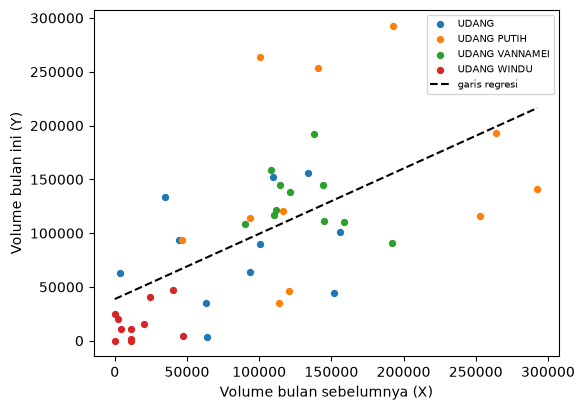

In [12]:
plt.figure(figsize=(6, 4.5))
for k, g in data.groupby('jenis_ikan'): plt.scatter(g['lag1'], g['volume'], s=18, label=k)
xs = np.linspace(0, data['lag1'].max(), 50)
plt.plot(xs, model.predict(pd.DataFrame({'lag1': xs})), 'k--', label='garis regresi')
plt.xlabel('Volume bulan sebelumnya (X)'); plt.ylabel('Volume bulan ini (Y)'); plt.legend(fontsize=7); plt.show()